# Q8 Practice: BTC Trend Satellite Validation

Q8 follows the Q7 conclusion: BTC should be tested only as a capped, trend-filtered satellite, not as a new core sleeve.

Core baseline remains the original three-asset RiskParity strategy:

- `510300.SS`: CSI 300 ETF
- `513100.SS`: Nasdaq 100 ETF
- `518880.SS`: Gold ETF

BTC is tested as `BTC-USD`, aligned to the ETF trading calendar. The main question is:

> Can a small BTC satellite, controlled by MA200 or SuperTrend, add convex upside without damaging the original RiskParity core?


## 1. Setup and Data Loading

BTC trades 7x24, while the ETF assets trade on exchange sessions. To keep strategy metrics comparable, all assets are evaluated only on the three ETF assets' common trading calendar. BTC prices are sampled on those dates.


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/q8-btc-trend-satellite")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CORE_SYMBOLS = ("510300.SS", "513100.SS", "518880.SS")
BTC_SYMBOL = "BTC-USD"
ALL_SYMBOLS = CORE_SYMBOLS + (BTC_SYMBOL,)
SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "518880.SS": "黄金ETF",
    "BTC-USD": "BTC",
}
START = "2016-06-21"
INITIAL_CAPITAL = 100_000
TRADING_DAYS = 252
REBALANCE_DAYS = 10
VOL_WINDOW = 20
BTC_MA_WINDOW = 200
ST_ATR = 10
ST_MULTIPLIER = 3.0
CAPS = [0.05, 0.10, 0.15]


In [2]:
def _flatten_yfinance_columns(df, symbol):
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [col[0] if col[1] == symbol else "_".join(map(str, col)).strip() for col in out.columns]
    out.columns = [str(c).lower().replace(" ", "_") for c in out.columns]
    return out


def download_symbol(symbol, start=START):
    df = yf.download(symbol, start=start, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {symbol}")
    df = _flatten_yfinance_columns(df, symbol)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise RuntimeError(f"{symbol} missing columns: {missing}")
    df = df[required].dropna(subset=["open", "high", "low", "close"])
    df.index = pd.DatetimeIndex(df.index).tz_localize(None).normalize()
    return df

raw = {sym: download_symbol(sym) for sym in ALL_SYMBOLS}
etf_index = raw[CORE_SYMBOLS[0]].index
for sym in CORE_SYMBOLS[1:]:
    etf_index = etf_index.intersection(raw[sym].index)
etf_index = etf_index.sort_values()

data = {}
for sym in CORE_SYMBOLS:
    data[sym] = raw[sym].reindex(etf_index).dropna(subset=["close"])
# BTC is sampled on ETF trading dates. Missing crypto rows, if any, are forward-filled before sampling.
btc_daily = raw[BTC_SYMBOL].sort_index().ffill()
data[BTC_SYMBOL] = btc_daily.reindex(etf_index, method="ffill").dropna(subset=["close"])

common_index = etf_index
for sym in ALL_SYMBOLS:
    common_index = common_index.intersection(data[sym].index)
common_index = common_index.sort_values()

data = {sym: data[sym].reindex(common_index).copy() for sym in ALL_SYMBOLS}
close = pd.DataFrame({sym: data[sym]["close"] for sym in ALL_SYMBOLS}).dropna()
open_ = pd.DataFrame({sym: data[sym]["open"] for sym in ALL_SYMBOLS}).reindex(close.index)
high = pd.DataFrame({sym: data[sym]["high"] for sym in ALL_SYMBOLS}).reindex(close.index)
low = pd.DataFrame({sym: data[sym]["low"] for sym in ALL_SYMBOLS}).reindex(close.index)
returns_cc = close.pct_change().fillna(0.0)
gap_returns = (open_ / close.shift(1) - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)
intraday_returns = (close / open_ - 1.0).replace([np.inf, -np.inf], np.nan).fillna(0.0)

print(f"共同样本: {close.index[0].date()} 到 {close.index[-1].date()}，{len(close)} 个ETF交易日")
for sym in ALL_SYMBOLS:
    print(f"{SYMBOL_NAMES[sym]}: {close[sym].iloc[-1] / close[sym].iloc[0] - 1:.2%}")


共同样本: 2016-06-21 到 2026-06-23，2426 个ETF交易日
沪深300ETF: 89.84%
纳指100ETF: 606.34%
黄金ETF: 215.60%
BTC: 9372.23%


## 2. Backtest And Indicator Helpers

组合统一保存目标权重、实际权重、换手率和成本。BTC 卫星策略采用固定上限：核心三资产 RiskParity 只占 `1 - cap`，BTC 不满足趋势时卫星仓位进入现金。


In [3]:
def normalize_weights(w, symbols=ALL_SYMBOLS):
    weights = {sym: float(max(0.0, w.get(sym, 0.0))) for sym in symbols}
    total = sum(weights.values())
    if total > 1.0 + 1e-12:
        weights = {sym: val / total for sym, val in weights.items()}
        total = 1.0
    weights["CASH"] = max(0.0, 1.0 - total)
    for sym in ALL_SYMBOLS:
        weights.setdefault(sym, 0.0)
    return weights


def risk_parity_weight(date, eligible, vol_window=VOL_WINDOW):
    eligible = list(eligible)
    if not eligible:
        return normalize_weights({})
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({})
    hist = returns_cc.iloc[loc - vol_window + 1 : loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({})
    inv = 1.0 / vols
    return normalize_weights((inv / inv.sum()).to_dict())


def make_rebalance_mask(index, every=REBALANCE_DAYS):
    mask = pd.Series(False, index=index)
    mask.iloc[::every] = True
    return mask


def build_targets(selector, allocator, rebalance_days=REBALANCE_DAYS):
    rebalance_mask = make_rebalance_mask(close.index, rebalance_days)
    rows = []
    last = normalize_weights({})
    for date in close.index:
        if bool(rebalance_mask.loc[date]):
            eligible = selector(date)
            last = allocator(date, eligible)
        rows.append(last)
    targets = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(ALL_SYMBOLS) + ["CASH"]:
        if col not in targets.columns:
            targets[col] = 0.0
    return targets[list(ALL_SYMBOLS) + ["CASH"]]


def backtest_targets(name, targets, execution="next_close", cost_bps=0.0):
    cost_rate = cost_bps / 10_000.0
    dates = close.index
    prev_weights = pd.Series(0.0, index=list(ALL_SYMBOLS) + ["CASH"])
    current_weights = prev_weights.copy()
    nav = []
    rets = []
    turnover = []
    costs = []
    held_rows = []
    value = INITIAL_CAPITAL

    for i, date in enumerate(dates):
        desired = targets.iloc[i - 1] if i > 0 else prev_weights
        desired = desired.reindex(prev_weights.index).fillna(0.0)

        if execution == "next_close":
            trade = (desired - current_weights).abs().sum() / 2.0
            gross = float((desired[list(ALL_SYMBOLS)] * returns_cc.loc[date, list(ALL_SYMBOLS)]).sum())
            cost = trade * cost_rate
            current_weights = desired.copy()
            day_ret = gross - cost
        elif execution == "next_open":
            gap = float((current_weights[list(ALL_SYMBOLS)] * gap_returns.loc[date, list(ALL_SYMBOLS)]).sum())
            value_after_gap = value * (1.0 + gap)
            trade = (desired - current_weights).abs().sum() / 2.0
            cost_cash = value_after_gap * trade * cost_rate
            value_after_trade = value_after_gap - cost_cash
            intraday = float((desired[list(ALL_SYMBOLS)] * intraday_returns.loc[date, list(ALL_SYMBOLS)]).sum())
            new_value = value_after_trade * (1.0 + intraday)
            day_ret = new_value / value - 1.0 if value > 0 else 0.0
            cost = cost_cash / value if value > 0 else 0.0
            current_weights = desired.copy()
        else:
            raise ValueError(f"Unknown execution: {execution}")

        value *= (1.0 + day_ret)
        nav.append(value)
        rets.append(day_ret)
        turnover.append(float(trade))
        costs.append(float(cost))
        held_rows.append(current_weights.to_dict())

    return {
        "name": name,
        "nav": pd.Series(nav, index=dates, name=name),
        "returns": pd.Series(rets, index=dates, name=name),
        "targets": targets,
        "weights": pd.DataFrame(held_rows, index=dates).fillna(0.0),
        "turnover": pd.Series(turnover, index=dates, name=name),
        "costs": pd.Series(costs, index=dates, name=name),
        "execution": execution,
        "cost_bps": cost_bps,
    }


In [4]:
def true_range(high_s, low_s, close_s):
    prev_close = close_s.shift(1)
    parts = pd.concat([
        high_s - low_s,
        (high_s - prev_close).abs(),
        (low_s - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1)


def supertrend_signal_for_symbol(sym, atr_period=ST_ATR, multiplier=ST_MULTIPLIER):
    h = high[sym]
    l = low[sym]
    c = close[sym]
    atr = true_range(h, l, c).rolling(atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr

    final_upper = pd.Series(index=c.index, dtype=float)
    final_lower = pd.Series(index=c.index, dtype=float)
    st = pd.Series(index=c.index, dtype=float)
    bullish = pd.Series(False, index=c.index, dtype=bool)

    for i, date in enumerate(c.index):
        if pd.isna(atr.iloc[i]):
            continue
        if i == 0 or pd.isna(final_upper.iloc[i - 1]):
            final_upper.iloc[i] = basic_upper.iloc[i]
            final_lower.iloc[i] = basic_lower.iloc[i]
            st.iloc[i] = final_upper.iloc[i]
            bullish.iloc[i] = False
            continue

        prev_date = c.index[i - 1]
        final_upper.iloc[i] = basic_upper.iloc[i] if (basic_upper.iloc[i] < final_upper.iloc[i - 1] or c.loc[prev_date] > final_upper.iloc[i - 1]) else final_upper.iloc[i - 1]
        final_lower.iloc[i] = basic_lower.iloc[i] if (basic_lower.iloc[i] > final_lower.iloc[i - 1] or c.loc[prev_date] < final_lower.iloc[i - 1]) else final_lower.iloc[i - 1]

        if st.iloc[i - 1] == final_upper.iloc[i - 1]:
            st.iloc[i] = final_lower.iloc[i] if c.iloc[i] > final_upper.iloc[i] else final_upper.iloc[i]
        else:
            st.iloc[i] = final_upper.iloc[i] if c.iloc[i] < final_lower.iloc[i] else final_lower.iloc[i]
        bullish.iloc[i] = c.iloc[i] > st.iloc[i]
    return st, bullish

_SUPERTREND_CACHE = {}
def supertrend_matrix(atr_period=ST_ATR, multiplier=ST_MULTIPLIER, symbols=ALL_SYMBOLS):
    key = (tuple(symbols), atr_period, float(multiplier))
    if key in _SUPERTREND_CACHE:
        return _SUPERTREND_CACHE[key]
    signals = {}
    lines = {}
    for sym in symbols:
        line, bull = supertrend_signal_for_symbol(sym, atr_period, multiplier)
        lines[sym] = line
        signals[sym] = bull
    result = (pd.DataFrame(signals), pd.DataFrame(lines))
    _SUPERTREND_CACHE[key] = result
    return result

btc_ma200 = close[BTC_SYMBOL].rolling(BTC_MA_WINDOW).mean()
btc_ma200_signal = close[BTC_SYMBOL] > btc_ma200
btc_st_signal = supertrend_matrix(ST_ATR, ST_MULTIPLIER, symbols=(BTC_SYMBOL,))[0][BTC_SYMBOL]
core_st_signal = supertrend_matrix(ST_ATR, ST_MULTIPLIER, symbols=CORE_SYMBOLS)[0]

print("Indicators ready: BTC MA200, BTC SuperTrend, core SuperTrend")


Indicators ready: BTC MA200, BTC SuperTrend, core SuperTrend


## 3. Strategy Constructors

Q8 将资产池变化、权重变化、timing filter 分开标注：

- 普通四资产 RiskParity 是资产池扩张对照组。
- BTC satellite 是核心三资产 RP + 固定上限 BTC。
- BTC trend satellite 只改变 BTC 是否启用，不让 BTC 进入核心风险平价权重。


In [5]:
def all_core_selector(_date):
    return list(CORE_SYMBOLS)


def all_four_selector(_date):
    return list(ALL_SYMBOLS)


def core_rp_allocator(date, eligible):
    return risk_parity_weight(date, eligible, VOL_WINDOW)


def run_core_rp(name="原三资产RiskParity", execution="next_close", cost_bps=0.0):
    targets = build_targets(all_core_selector, core_rp_allocator)
    return backtest_targets(name, targets, execution=execution, cost_bps=cost_bps)


def run_four_asset_rp(name="四资产普通RiskParity", execution="next_close", cost_bps=0.0):
    targets = build_targets(all_four_selector, core_rp_allocator)
    return backtest_targets(name, targets, execution=execution, cost_bps=cost_bps)


def core_supertrend_selector(date):
    row = core_st_signal.loc[date]
    return [sym for sym in CORE_SYMBOLS if bool(row.get(sym, False))]


def run_core_supertrend_rp(name="SuperTrend三资产+RiskParity", execution="next_close", cost_bps=0.0):
    targets = build_targets(core_supertrend_selector, core_rp_allocator)
    return backtest_targets(name, targets, execution=execution, cost_bps=cost_bps)


def satellite_allocator_factory(cap, signal_series=None):
    def _allocator(date, _eligible):
        core = risk_parity_weight(date, CORE_SYMBOLS, VOL_WINDOW)
        weights = {sym: core.get(sym, 0.0) * (1.0 - cap) for sym in CORE_SYMBOLS}
        btc_on = True if signal_series is None else bool(signal_series.loc[date])
        weights[BTC_SYMBOL] = cap if btc_on else 0.0
        return normalize_weights(weights)
    return _allocator


def run_btc_satellite(name, cap, signal_series=None, execution="next_close", cost_bps=0.0):
    targets = build_targets(lambda _date: list(ALL_SYMBOLS), satellite_allocator_factory(cap, signal_series))
    return backtest_targets(name, targets, execution=execution, cost_bps=cost_bps)


## 4. Main Q8 Strategy Runs

主比较包括：原核心、Q7 SuperTrend 对照、四资产普通 RP、BTC 无过滤卫星、BTC MA200 卫星、BTC SuperTrend 卫星。


In [6]:
main_results = {
    "原三资产RiskParity": run_core_rp(),
    "SuperTrend三资产+RiskParity": run_core_supertrend_rp(),
    "四资产普通RiskParity": run_four_asset_rp(),
}
for cap in CAPS:
    pct = int(cap * 100)
    main_results[f"BTC{pct}%无过滤卫星"] = run_btc_satellite(f"BTC{pct}%无过滤卫星", cap, signal_series=None)
    main_results[f"BTC{pct}%MA200卫星"] = run_btc_satellite(f"BTC{pct}%MA200卫星", cap, signal_series=btc_ma200_signal)
    main_results[f"BTC{pct}%SuperTrend卫星"] = run_btc_satellite(f"BTC{pct}%SuperTrend卫星", cap, signal_series=btc_st_signal)

print(f"策略数量: {len(main_results)}")
print(list(main_results))


策略数量: 12
['原三资产RiskParity', 'SuperTrend三资产+RiskParity', '四资产普通RiskParity', 'BTC5%无过滤卫星', 'BTC5%MA200卫星', 'BTC5%SuperTrend卫星', 'BTC10%无过滤卫星', 'BTC10%MA200卫星', 'BTC10%SuperTrend卫星', 'BTC15%无过滤卫星', 'BTC15%MA200卫星', 'BTC15%SuperTrend卫星']


## 5. Q3/Q5 Metrics


In [7]:
def drawdown(nav_s):
    return nav_s / nav_s.cummax() - 1.0


def strategy_metrics(result):
    nav_s = result["nav"].dropna()
    ret_s = result["returns"].reindex(nav_s.index).fillna(0.0)
    total = nav_s.iloc[-1] / nav_s.iloc[0] - 1.0
    annual = (nav_s.iloc[-1] / nav_s.iloc[0]) ** (TRADING_DAYS / (len(nav_s) - 1)) - 1.0
    vol = ret_s.std(ddof=1) * np.sqrt(TRADING_DAYS)
    max_dd = drawdown(nav_s).min()
    sharpe = (ret_s.mean() * TRADING_DAYS) / vol if vol > 0 else np.nan
    calmar = annual / abs(max_dd) if max_dd < 0 else np.nan
    downside = ret_s[ret_s < 0]
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(TRADING_DAYS) if len(downside) else np.nan
    sortino = (ret_s.mean() * TRADING_DAYS) / downside_dev if downside_dev and downside_dev > 0 else np.nan
    weights = result["weights"].reindex(nav_s.index).fillna(0.0)
    turnover = result["turnover"].reindex(nav_s.index).fillna(0.0)
    costs = result["costs"].reindex(nav_s.index).fillna(0.0)
    row = {
        "累计收益": total,
        "年化收益": annual,
        "年化波动": vol,
        "最大回撤": max_dd,
        "夏普": sharpe,
        "卡玛": calmar,
        "索提诺": sortino,
        "平均现金": weights["CASH"].mean(),
        "年化换手": turnover.mean() * TRADING_DAYS,
        "成本拖累": costs.sum(),
    }
    for sym in ALL_SYMBOLS:
        row[f"当前权重_{SYMBOL_NAMES[sym]}"] = weights[sym].iloc[-1]
        row[f"平均权重_{SYMBOL_NAMES[sym]}"] = weights[sym].mean()
    return row


def monthly_returns(nav_s):
    month_end = nav_s.resample("ME").last()
    return month_end.pct_change().dropna()


def annual_returns(nav_s):
    year_end = nav_s.resample("YE").last()
    prev = pd.concat([pd.Series([nav_s.iloc[0]], index=[nav_s.index[0]]), year_end])
    out = prev.pct_change().dropna()
    out.index = out.index.year
    return out


def max_consecutive(mask):
    longest = 0
    current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def monthly_stats(result):
    months = monthly_returns(result["nav"])
    gains = months[months > 0]
    losses = months[months < 0]
    total_gain = gains.sum()
    total_loss = losses.sum()
    avg_gain = gains.mean() if len(gains) else 0.0
    avg_loss = losses.mean() if len(losses) else 0.0
    return {
        "总月数": len(months),
        "盈利月数": len(gains),
        "亏损月数": len(losses),
        "月度胜率": len(gains) / len(months) if len(months) else np.nan,
        "平均盈利月": avg_gain,
        "平均亏损月": avg_loss,
        "盈亏比": avg_gain / abs(avg_loss) if avg_loss != 0 else np.nan,
        "盈亏因子": total_gain / abs(total_loss) if total_loss != 0 else np.nan,
        "最好月": months.max() if len(months) else np.nan,
        "最差月": months.min() if len(months) else np.nan,
        "最长连赢": max_consecutive(months > 0),
        "最长连亏": max_consecutive(months < 0),
    }

q3_metrics = pd.DataFrame({name: strategy_metrics(result) for name, result in main_results.items()}).T
baseline_total = q3_metrics.loc["原三资产RiskParity", "累计收益"]
q5_metrics = q3_metrics[["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛", "索提诺", "平均现金", "年化换手", "成本拖累"]].copy()
q5_metrics["Alpha_vs_RP基准"] = q5_metrics["累计收益"] - baseline_total
q5_metrics = q5_metrics.join(pd.DataFrame({name: monthly_stats(result) for name, result in main_results.items()}).T)
q3_metrics.to_csv(OUTPUT_DIR / "q3_metrics.csv", encoding="utf-8-sig")
q5_metrics.to_csv(OUTPUT_DIR / "q5_metrics.csv", encoding="utf-8-sig")
pd.DataFrame({name: result["weights"].iloc[-1] for name, result in main_results.items()}).T.to_csv(OUTPUT_DIR / "latest_weights.csv", encoding="utf-8-sig")
pd.DataFrame({name: result["weights"].mean() for name, result in main_results.items()}).T.to_csv(OUTPUT_DIR / "average_weights.csv", encoding="utf-8-sig")

q5_metrics.sort_values("卡玛", ascending=False).round(4)


,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛,索提诺,平均现金,年化换手,成本拖累,...,亏损月数,月度胜率,平均盈利月,平均亏损月,盈亏比,盈亏因子,最好月,最差月,最长连赢,最长连亏
BTC10%SuperTrend卫星,5.1486,0.2077,0.1125,-0.1281,1.7338,1.6210,1.6761,0.0530,2.4324,0.0,...,38.0,0.6833,0.0312,-0.0177,1.7662,3.8113,0.1105,-0.0676,8.0,6.0
BTC15%SuperTrend卫星,6.4732,0.2325,0.1209,-0.1500,1.7889,1.5493,1.7691,0.0753,2.6579,0.0,...,40.0,0.6667,0.0357,-0.0189,1.8921,3.7842,0.1288,-0.0690,8.0,6.0
BTC10%MA200卫星,5.3444,0.2117,0.1157,-0.1468,1.7174,1.4419,1.6838,0.0460,1.9546,0.0,...,41.0,0.6583,0.0334,-0.0174,1.9221,3.7036,0.1105,-0.0676,8.0,6.0
BTC15%MA200卫星,6.8170,0.2382,0.1271,-0.1671,1.7452,1.4259,1.7704,0.0648,1.9412,0.0,...,42.0,0.6500,0.0382,-0.0195,1.9548,3.6304,0.1288,-0.0673,8.0,4.0
BTC5%SuperTrend卫星,4.0276,0.1827,0.1094,-0.1293,1.5882,1.4128,1.5103,0.0306,2.2069,0.0,...,39.0,0.6750,0.0288,-0.0168,1.7179,3.5679,0.0979,-0.0713,8.0,4.0
BTC5%MA200卫星,4.1106,0.1847,0.1104,-0.1346,1.5903,1.3722,1.5139,0.0271,1.9680,0.0,...,38.0,0.6833,0.0286,-0.0171,1.6714,3.6068,0.0979,-0.0713,13.0,4.0
BTC5%无过滤卫星,4.3189,0.1897,0.1134,-0.1551,1.5876,1.2227,1.5087,0.0078,1.8849,0.0,...,37.0,0.6917,0.0297,-0.0196,1.5169,3.4027,0.0999,-0.0693,13.0,5.0
BTC10%无过滤卫星,5.8470,0.2213,0.1245,-0.1886,1.6687,1.1731,1.6133,0.0074,1.7884,0.0,...,39.0,0.6750,0.0359,-0.0228,1.5746,3.2703,0.1124,-0.0736,8.0,5.0
原三资产RiskParity,3.0858,0.1575,0.1121,-0.1353,1.3602,1.1640,1.2817,0.0082,1.9813,0.0,...,42.0,0.6500,0.0278,-0.0167,1.6639,3.0901,0.0922,-0.0750,11.0,4.0
四资产普通RiskParity,4.5071,0.1940,0.1197,-0.1744,1.5406,1.1120,1.4419,0.0082,2.1207,0.0,...,35.0,0.7083,0.0312,-0.0246,1.2680,3.0795,0.1195,-0.0773,19.0,5.0


## 6. Annual Returns, Monthly Distribution, And NAV Charts


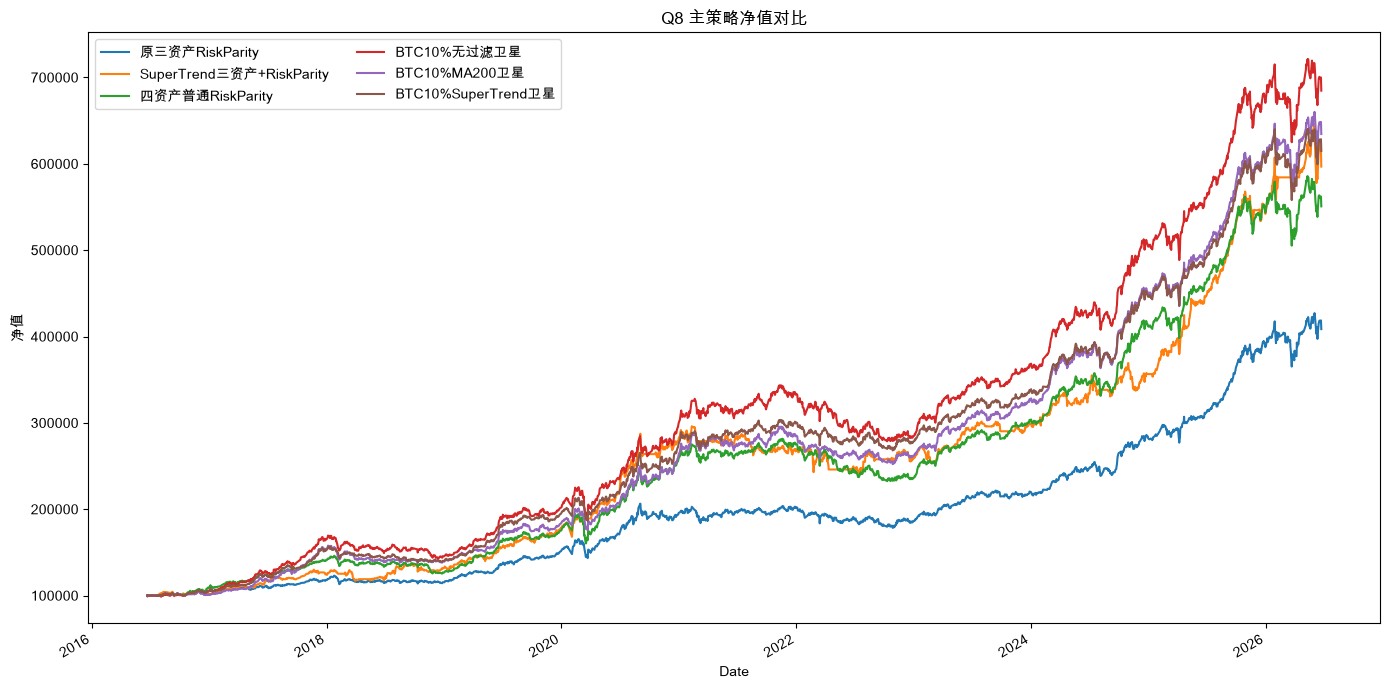

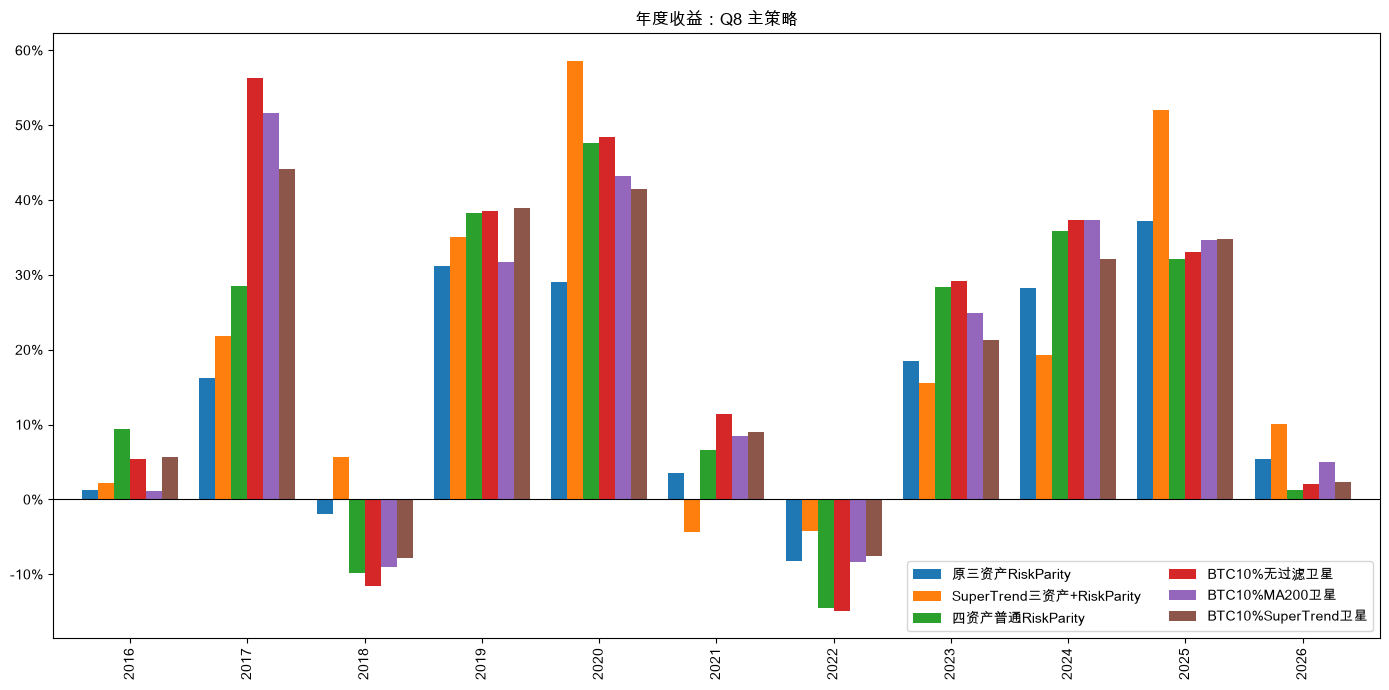

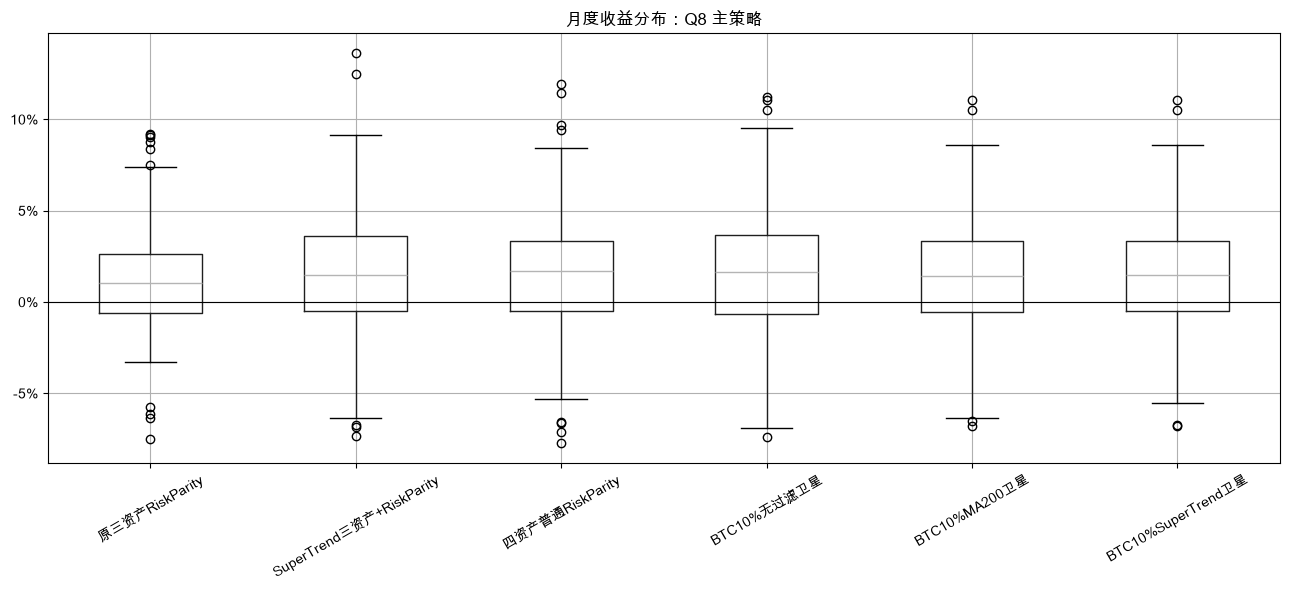

,原三资产RiskParity,SuperTrend三资产+RiskParity,四资产普通RiskParity,BTC10%无过滤卫星,BTC10%MA200卫星,BTC10%SuperTrend卫星
2016,0.0131,0.0223,0.0945,0.0536,0.0119,0.0561
2017,0.1624,0.2189,0.2853,0.5635,0.5159,0.4418
2018,-0.0193,0.0571,-0.0983,-0.1158,-0.0908,-0.0788
2019,0.3121,0.3505,0.3824,0.3860,0.3169,0.3899
2020,0.2911,0.5859,0.4767,0.4846,0.4327,0.4148
2021,0.0348,-0.0440,0.0658,0.1140,0.0849,0.0901
2022,-0.0819,-0.0416,-0.1450,-0.1487,-0.0834,-0.0750
2023,0.1854,0.1556,0.2844,0.2912,0.2493,0.2136
2024,0.2822,0.1936,0.3584,0.3739,0.3739,0.3213
2025,0.3717,0.5203,0.3207,0.3300,0.3460,0.3473


In [8]:
nav_table = pd.DataFrame({name: result["nav"] for name, result in main_results.items()})
nav_table.to_csv(OUTPUT_DIR / "nav_all_strategies.csv", encoding="utf-8-sig")
annual_table = pd.DataFrame({name: annual_returns(result["nav"]) for name, result in main_results.items()})
annual_table.to_csv(OUTPUT_DIR / "annual_returns.csv", encoding="utf-8-sig")
monthly_table = pd.DataFrame({name: monthly_returns(result["nav"]) for name, result in main_results.items()})
monthly_table.to_csv(OUTPUT_DIR / "monthly_returns.csv", encoding="utf-8-sig")
pd.DataFrame({name: monthly_stats(result) for name, result in main_results.items()}).T.to_csv(OUTPUT_DIR / "monthly_stats.csv", encoding="utf-8-sig")

plot_names = [
    "原三资产RiskParity",
    "SuperTrend三资产+RiskParity",
    "四资产普通RiskParity",
    "BTC10%无过滤卫星",
    "BTC10%MA200卫星",
    "BTC10%SuperTrend卫星",
]
fig, ax = plt.subplots(figsize=(14, 7))
nav_table[plot_names].plot(ax=ax)
ax.set_title("Q8 主策略净值对比")
ax.set_ylabel("净值")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nav_main_comparison.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(14, 7))
annual_table[plot_names].plot(kind="bar", ax=ax, width=0.82)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("年度收益：Q8 主策略")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "annual_returns_main.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(13, 6))
monthly_table[plot_names].boxplot(ax=ax, rot=30)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("月度收益分布：Q8 主策略")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "monthly_distribution_main.png", dpi=160)
plt.show()

annual_table[plot_names].round(4)


## 7. Drawdown Events And Underwater Curves


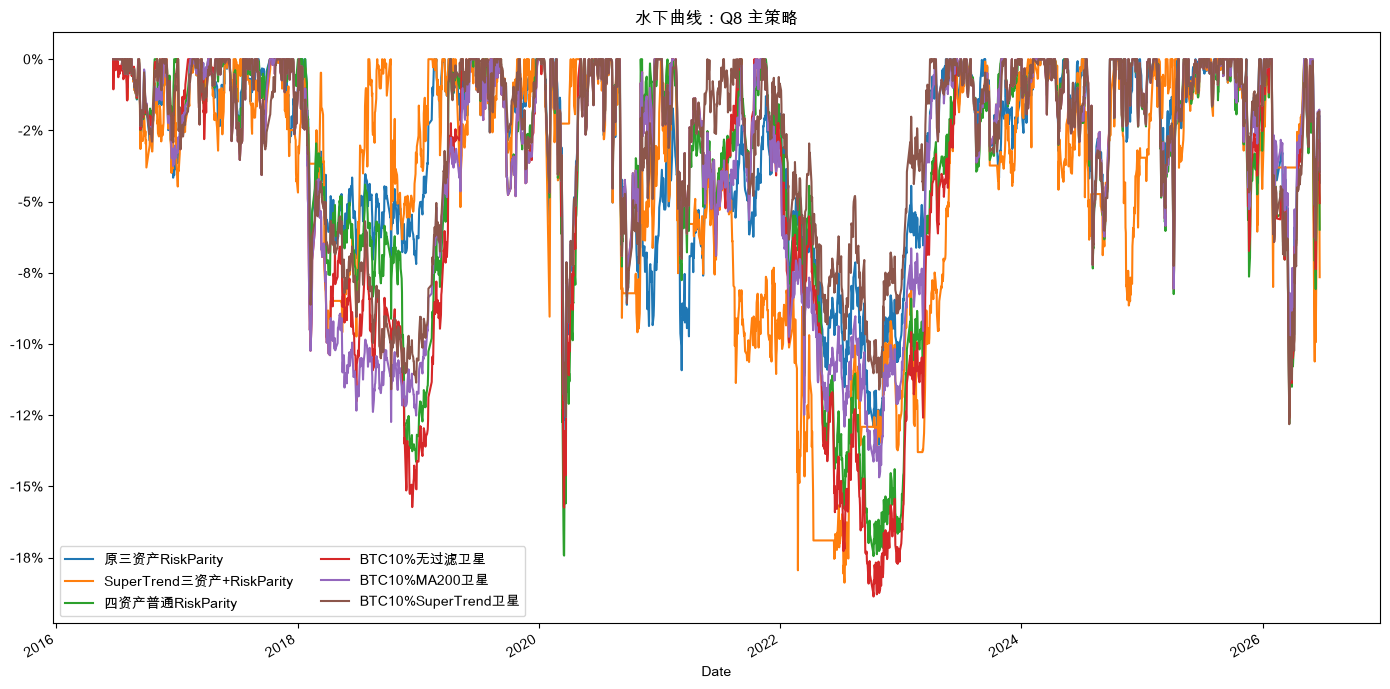

,最大回撤,平均回撤深度,平均恢复天数,最长恢复天数,回撤次数
原三资产RiskParity,-0.1353,-0.0152,12.4044,376.0,137.0
SuperTrend三资产+RiskParity,-0.1838,-0.0174,12.9783,363.0,139.0
四资产普通RiskParity,-0.1744,-0.0170,12.0556,248.0,145.0
BTC10%无过滤卫星,-0.1886,-0.0175,12.0070,252.0,144.0
BTC10%MA200卫星,-0.1468,-0.0157,12.4384,242.0,147.0
BTC10%SuperTrend卫星,-0.1281,-0.0159,11.1299,179.0,155.0


In [9]:
def drawdown_events(result):
    dd = drawdown(result["nav"]).dropna()
    events = []
    in_dd = False
    start = trough = None
    trough_value = 0.0
    for date, value in dd.items():
        if not in_dd and value < 0:
            in_dd = True
            start = trough = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough = date
                trough_value = value
            if value >= 0:
                events.append({
                    "开始日期": pd.Timestamp(start).date(),
                    "最低点日期": pd.Timestamp(trough).date(),
                    "恢复日期": pd.Timestamp(date).date(),
                    "深度": trough_value,
                    "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
                    "恢复天数": (pd.Timestamp(date) - pd.Timestamp(trough)).days,
                    "总持续天数": (pd.Timestamp(date) - pd.Timestamp(start)).days,
                })
                in_dd = False
                start = trough = None
                trough_value = 0.0
    if in_dd and start is not None:
        last = dd.index[-1]
        events.append({
            "开始日期": pd.Timestamp(start).date(),
            "最低点日期": pd.Timestamp(trough).date(),
            "恢复日期": "未恢复",
            "深度": trough_value,
            "下跌天数": (pd.Timestamp(trough) - pd.Timestamp(start)).days,
            "恢复天数": np.nan,
            "总持续天数": (pd.Timestamp(last) - pd.Timestamp(start)).days,
        })
    return pd.DataFrame(events).sort_values("深度") if events else pd.DataFrame()


def drawdown_summary(result):
    events = drawdown_events(result)
    if events.empty:
        return {"最大回撤": 0.0, "平均回撤深度": 0.0, "平均恢复天数": np.nan, "最长恢复天数": np.nan, "回撤次数": 0}
    recovered = events[pd.to_numeric(events["恢复天数"], errors="coerce").notna()].copy()
    return {
        "最大回撤": events["深度"].min(),
        "平均回撤深度": events["深度"].mean(),
        "平均恢复天数": recovered["恢复天数"].mean() if len(recovered) else np.nan,
        "最长恢复天数": recovered["恢复天数"].max() if len(recovered) else np.nan,
        "回撤次数": len(events),
    }

dd_summary = pd.DataFrame({name: drawdown_summary(result) for name, result in main_results.items()}).T
dd_summary.to_csv(OUTPUT_DIR / "drawdown_summary.csv", encoding="utf-8-sig")
for name, result in main_results.items():
    drawdown_events(result).head(10).to_csv(OUTPUT_DIR / f"drawdown_events_{name}.csv", encoding="utf-8-sig", index=False)
underwater = nav_table.apply(drawdown)
underwater.to_csv(OUTPUT_DIR / "underwater_curves.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(14, 7))
underwater[plot_names].plot(ax=ax)
ax.set_title("水下曲线：Q8 主策略")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "underwater_main.png", dpi=160)
plt.show()

dd_summary.loc[plot_names].round(4)


## 8. BTC Cap And Filter Sensitivity

小网格检查 cap 从 5% 到 15% 时，裸 BTC、MA200 BTC、SuperTrend BTC 的形状是否稳定。


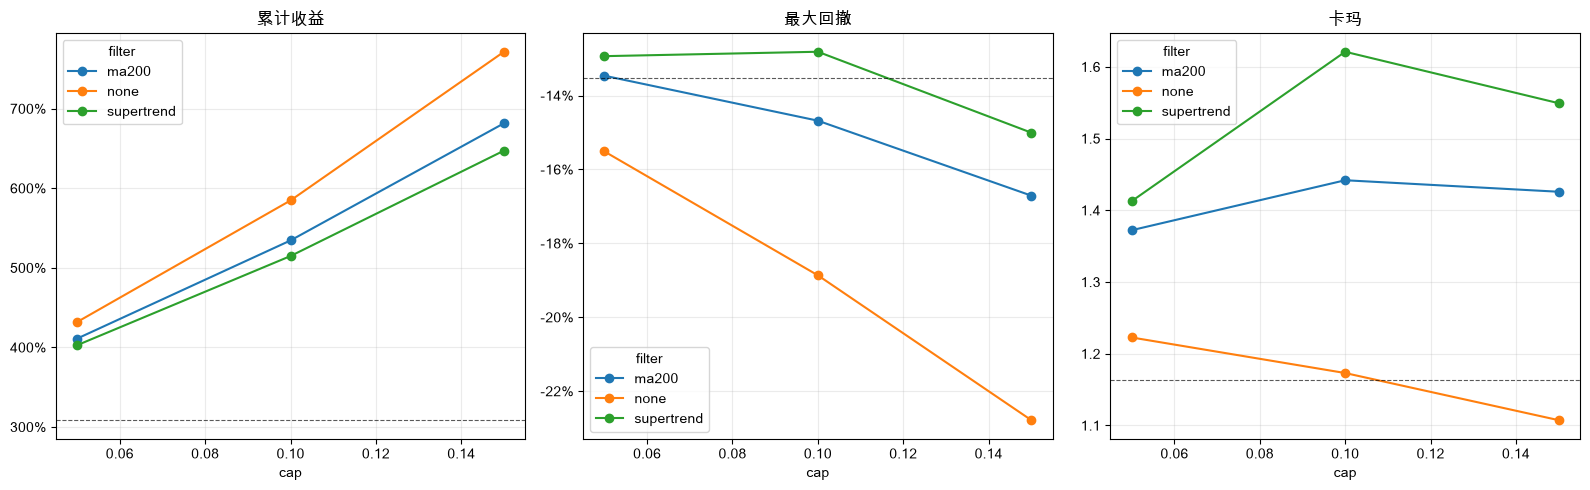

,cap,filter,策略,累计收益,年化收益,最大回撤,夏普,卡玛,平均权重_BTC,平均现金,Alpha_vs_RP基准
0,0.05,none,BTC5%无过滤卫星,4.3189,0.1897,-0.1551,1.5876,1.2227,0.0500,0.0078,1.2331
1,0.05,ma200,BTC5%MA200卫星,4.1106,0.1847,-0.1346,1.5903,1.3722,0.0307,0.0271,1.0249
2,0.05,supertrend,BTC5%SuperTrend卫星,4.0276,0.1827,-0.1293,1.5882,1.4128,0.0272,0.0306,0.9419
3,0.10,none,BTC10%无过滤卫星,5.8470,0.2213,-0.1886,1.6687,1.1731,0.1000,0.0074,2.7612
4,0.10,ma200,BTC10%MA200卫星,5.3444,0.2117,-0.1468,1.7174,1.4419,0.0614,0.0460,2.2587
5,0.10,supertrend,BTC10%SuperTrend卫星,5.1486,0.2077,-0.1281,1.7338,1.6210,0.0544,0.0530,2.0628
6,0.15,none,BTC15%无过滤卫星,7.7159,0.2523,-0.2278,1.6457,1.1074,0.1499,0.0070,4.6301
7,0.15,ma200,BTC15%MA200卫星,6.8170,0.2382,-0.1671,1.7452,1.4259,0.0921,0.0648,3.7312
8,0.15,supertrend,BTC15%SuperTrend卫星,6.4732,0.2325,-0.1500,1.7889,1.5493,0.0816,0.0753,3.3875


In [10]:
cap_rows = []
for cap in CAPS:
    pct = int(cap * 100)
    for filter_name, strategy_name in [
        ("none", f"BTC{pct}%无过滤卫星"),
        ("ma200", f"BTC{pct}%MA200卫星"),
        ("supertrend", f"BTC{pct}%SuperTrend卫星"),
    ]:
        row = strategy_metrics(main_results[strategy_name])
        row["cap"] = cap
        row["filter"] = filter_name
        row["策略"] = strategy_name
        row["Alpha_vs_RP基准"] = row["累计收益"] - baseline_total
        cap_rows.append(row)
cap_sensitivity = pd.DataFrame(cap_rows)
cap_sensitivity.to_csv(OUTPUT_DIR / "btc_cap_filter_sensitivity.csv", encoding="utf-8-sig", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for metric, ax in [("累计收益", axes[0]), ("最大回撤", axes[1]), ("卡玛", axes[2])]:
    pivot = cap_sensitivity.pivot(index="cap", columns="filter", values=metric)
    pivot.plot(marker="o", ax=ax)
    ax.axhline(q5_metrics.loc["原三资产RiskParity", metric], color="black", linestyle="--", linewidth=0.8, alpha=0.65)
    ax.set_title(metric)
    ax.grid(True, alpha=0.25)
    if metric in ["累计收益", "最大回撤"]:
        ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "btc_cap_filter_sensitivity.png", dpi=160)
plt.show()

cap_sensitivity[["cap", "filter", "策略", "累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "平均权重_BTC", "平均现金", "Alpha_vs_RP基准"]].round(4)


## 9. Cost And Next-Open Execution Check

只对关键策略跑成本/执行压力测试：原 RP、Q7 SuperTrend 对照、四资产普通 RP、10% BTC 无过滤卫星、10% BTC MA200 卫星、10% BTC SuperTrend 卫星。


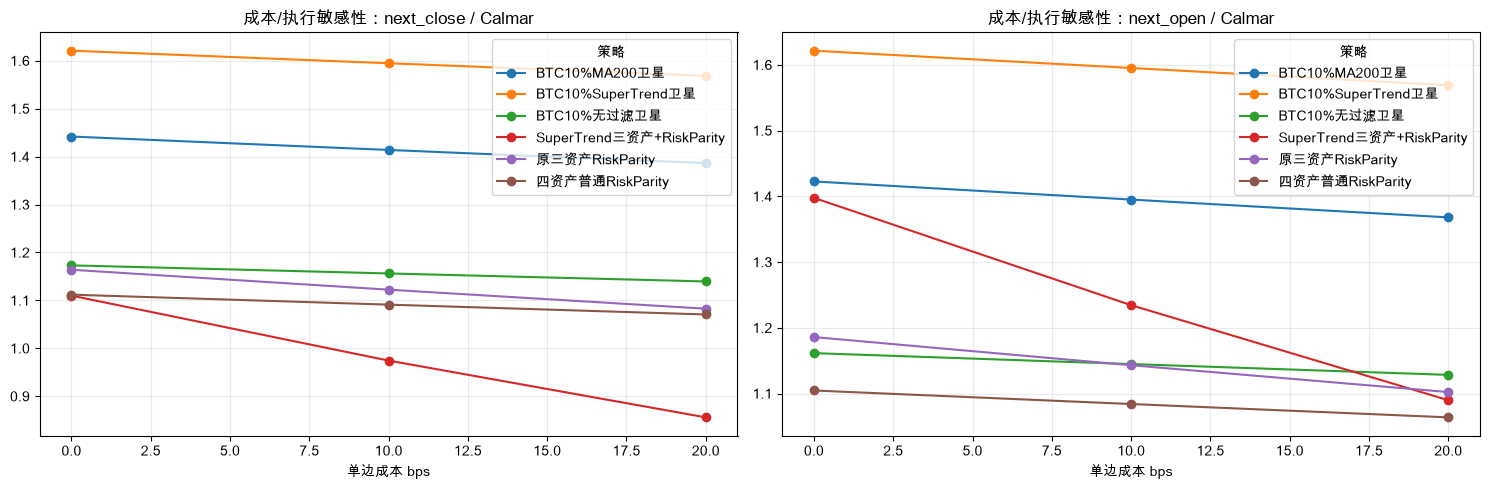

,execution,cost_bps,策略,累计收益,最大回撤,夏普,卡玛,年化换手,成本拖累,Alpha_vs_RP同成本
0,next_close,0,原三资产RiskParity,3.0858,-0.1353,1.3602,1.1640,1.9813,0.0000,0.0000
1,next_close,0,SuperTrend三资产+RiskParity,4.9675,-0.1838,1.4416,1.1100,10.9424,0.0000,1.8817
2,next_close,0,四资产普通RiskParity,4.5071,-0.1744,1.5406,1.1120,2.1207,0.0000,1.4213
3,next_close,0,BTC10%无过滤卫星,5.8470,-0.1886,1.6687,1.1731,1.7884,0.0000,2.7612
4,next_close,0,BTC10%MA200卫星,5.3444,-0.1468,1.7174,1.4419,1.9546,0.0000,2.2587
5,next_close,0,BTC10%SuperTrend卫星,5.1486,-0.1281,1.7338,1.6210,2.4324,0.0000,2.0628
6,next_close,10,原三资产RiskParity,3.0086,-0.1383,1.3427,1.1224,1.9813,0.0191,0.0000
7,next_close,10,SuperTrend三资产+RiskParity,4.3708,-0.1959,1.3600,0.9744,10.9424,0.1053,1.3622
8,next_close,10,四资产普通RiskParity,4.3959,-0.1754,1.5231,1.0912,2.1207,0.0204,1.3873
9,next_close,10,BTC10%无过滤卫星,5.7303,-0.1895,1.6544,1.1562,1.7884,0.0172,2.7216


In [11]:
def run_named_strategy(name, execution="next_close", cost_bps=0.0):
    if name == "原三资产RiskParity":
        return run_core_rp(name, execution=execution, cost_bps=cost_bps)
    if name == "SuperTrend三资产+RiskParity":
        return run_core_supertrend_rp(name, execution=execution, cost_bps=cost_bps)
    if name == "四资产普通RiskParity":
        return run_four_asset_rp(name, execution=execution, cost_bps=cost_bps)
    if name == "BTC10%无过滤卫星":
        return run_btc_satellite(name, 0.10, signal_series=None, execution=execution, cost_bps=cost_bps)
    if name == "BTC10%MA200卫星":
        return run_btc_satellite(name, 0.10, signal_series=btc_ma200_signal, execution=execution, cost_bps=cost_bps)
    if name == "BTC10%SuperTrend卫星":
        return run_btc_satellite(name, 0.10, signal_series=btc_st_signal, execution=execution, cost_bps=cost_bps)
    raise ValueError(name)

cost_names = [
    "原三资产RiskParity",
    "SuperTrend三资产+RiskParity",
    "四资产普通RiskParity",
    "BTC10%无过滤卫星",
    "BTC10%MA200卫星",
    "BTC10%SuperTrend卫星",
]
cost_rows = []
for execution in ["next_close", "next_open"]:
    for cost_bps in [0, 10, 20]:
        batch = {name: run_named_strategy(name, execution=execution, cost_bps=cost_bps) for name in cost_names}
        rp_total = strategy_metrics(batch["原三资产RiskParity"])["累计收益"]
        for name, result in batch.items():
            row = strategy_metrics(result)
            row["策略"] = name
            row["execution"] = execution
            row["cost_bps"] = cost_bps
            row["Alpha_vs_RP同成本"] = row["累计收益"] - rp_total
            cost_rows.append(row)
cost_execution = pd.DataFrame(cost_rows)
cost_execution.to_csv(OUTPUT_DIR / "cost_execution_sensitivity.csv", encoding="utf-8-sig", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for execution, ax in zip(["next_close", "next_open"], axes):
    sub = cost_execution[cost_execution["execution"] == execution]
    pivot = sub.pivot(index="cost_bps", columns="策略", values="卡玛")
    pivot.plot(marker="o", ax=ax)
    ax.set_title(f"成本/执行敏感性：{execution} / Calmar")
    ax.set_xlabel("单边成本 bps")
    ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cost_execution_sensitivity.png", dpi=160)
plt.show()

cost_execution[["execution", "cost_bps", "策略", "累计收益", "最大回撤", "夏普", "卡玛", "年化换手", "成本拖累", "Alpha_vs_RP同成本"]].round(4)


## 10. Decision Scorecard

Q8 的通过标准更严格：BTC 不能只提高累计收益，还要尽量不破坏 Calmar、最大回撤、最差月/年和恢复结构。


In [12]:
score_names = [
    "四资产普通RiskParity",
    "BTC5%无过滤卫星",
    "BTC5%MA200卫星",
    "BTC5%SuperTrend卫星",
    "BTC10%无过滤卫星",
    "BTC10%MA200卫星",
    "BTC10%SuperTrend卫星",
    "BTC15%无过滤卫星",
    "BTC15%MA200卫星",
    "BTC15%SuperTrend卫星",
]
rp = q5_metrics.loc["原三资产RiskParity"]
score_rows = []
for name in score_names:
    row = q5_metrics.loc[name]
    annual = annual_table[name]
    score_rows.append({
        "策略": name,
        "累计收益提升": row["累计收益"] > rp["累计收益"],
        "Sharpe提升": row["夏普"] > rp["夏普"],
        "Calmar不低于RP": row["卡玛"] >= rp["卡玛"],
        "最大回撤不深于RP": row["最大回撤"] >= rp["最大回撤"],
        "最差月不差于RP": row["最差月"] >= rp["最差月"],
        "最差年不差于RP": annual.min() >= annual_table["原三资产RiskParity"].min(),
        "累计收益": row["累计收益"],
        "最大回撤": row["最大回撤"],
        "夏普": row["夏普"],
        "卡玛": row["卡玛"],
        "最差月": row["最差月"],
        "最差年": annual.min(),
        "平均BTC权重": q3_metrics.loc[name, "平均权重_BTC"],
    })
decision_scorecard = pd.DataFrame(score_rows)
decision_scorecard["通过项数"] = decision_scorecard[["累计收益提升", "Sharpe提升", "Calmar不低于RP", "最大回撤不深于RP", "最差月不差于RP", "最差年不差于RP"]].sum(axis=1)
decision_scorecard.to_csv(OUTPUT_DIR / "decision_scorecard.csv", encoding="utf-8-sig", index=False)

q8_summary = pd.Series({
    "sample_start": str(close.index[0].date()),
    "sample_end": str(close.index[-1].date()),
    "historical_best": q5_metrics["累计收益"].idxmax(),
    "sharpe_best": q5_metrics["夏普"].idxmax(),
    "calmar_best": q5_metrics["卡玛"].idxmax(),
    "lowest_drawdown": q5_metrics["最大回撤"].idxmax(),
    "best_btc_candidate_by_calmar": decision_scorecard.sort_values("卡玛", ascending=False).iloc[0]["策略"],
    "best_btc_candidate_by_pass_count": decision_scorecard.sort_values(["通过项数", "卡玛"], ascending=False).iloc[0]["策略"],
})
q8_summary.to_csv(OUTPUT_DIR / "research_summary.csv", encoding="utf-8-sig")

decision_scorecard.sort_values(["通过项数", "卡玛"], ascending=False).round(4)


,策略,累计收益提升,Sharpe提升,Calmar不低于RP,最大回撤不深于RP,最差月不差于RP,最差年不差于RP,累计收益,最大回撤,夏普,卡玛,最差月,最差年,平均BTC权重,通过项数
6,BTC10%SuperTrend卫星,True,True,True,True,True,True,5.1486,-0.1281,1.7338,1.6210,-0.0676,-0.0788,0.0544,6
3,BTC5%SuperTrend卫星,True,True,True,True,True,True,4.0276,-0.1293,1.5882,1.4128,-0.0713,-0.0784,0.0272,6
2,BTC5%MA200卫星,True,True,True,True,True,False,4.1106,-0.1346,1.5903,1.3722,-0.0713,-0.0826,0.0307,5
9,BTC15%SuperTrend卫星,True,True,True,False,True,False,6.4732,-0.1500,1.7889,1.5493,-0.0690,-0.1076,0.0816,4
5,BTC10%MA200卫星,True,True,True,False,True,False,5.3444,-0.1468,1.7174,1.4419,-0.0676,-0.0908,0.0614,4
8,BTC15%MA200卫星,True,True,True,False,True,False,6.8170,-0.1671,1.7452,1.4259,-0.0673,-0.1255,0.0921,4
1,BTC5%无过滤卫星,True,True,True,False,True,False,4.3189,-0.1551,1.5876,1.2227,-0.0693,-0.1155,0.0500,4
4,BTC10%无过滤卫星,True,True,True,False,True,False,5.8470,-0.1886,1.6687,1.1731,-0.0736,-0.1487,0.1000,4
0,四资产普通RiskParity,True,True,False,False,False,False,4.5071,-0.1744,1.5406,1.1120,-0.0773,-0.1450,0.0828,2
7,BTC15%无过滤卫星,True,True,False,False,False,False,7.7159,-0.2278,1.6457,1.1074,-0.0797,-0.1815,0.1499,2


## 11. Plain-Language Conclusion Template

- Historical best:
- Risk-adjusted best:
- Most structurally balanced:
- Main sample-period advantage:
- Main future failure mode:
- BTC decision:
- What to test next:
